In [18]:
import re
import numpy as np
import matplotlib.pyplot as plt

def parse_iqae_ceiling_file(filepath):
    """
    Parse an IQAE ceiling-mode frontier data export file.
    Extracts run parameter N_SHOTS and frontier columns: epsilon, p_star.

    Returns:
        epsilon  : np.ndarray
        p_star   : np.ndarray
        n_shots  : int
    """
    epsilons = []
    p_stars  = []
    n_shots  = None

    with open(filepath, "r") as f:
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        # ── Extract N_SHOTS from [RUN PARAMETERS] ─────────────────────────────
        if line.startswith("N_SHOTS"):
            n_shots = int(line.split(":")[1].strip())
            continue

        # ── Detect start of data section ──────────────────────────────────────
        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue  # skip the header row

        # ── Skip separator line ───────────────────────────────────────────────
        if in_data_section and set(line) <= set("-"):
            continue

        # ── Parse data rows ───────────────────────────────────────────────────
        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))

    return (
        np.array(epsilons),
        np.array(p_stars),
        n_shots,
    )


# ── Usage ─────────────────────────────────────────────────────────────────────
ALPHA = 0.05
epsilon, p_star, n_shots = parse_iqae_ceiling_file("data100.txt")

print(f"N_SHOTS: {n_shots}")  # N_SHOTS: 100

N_SHOTS: 100


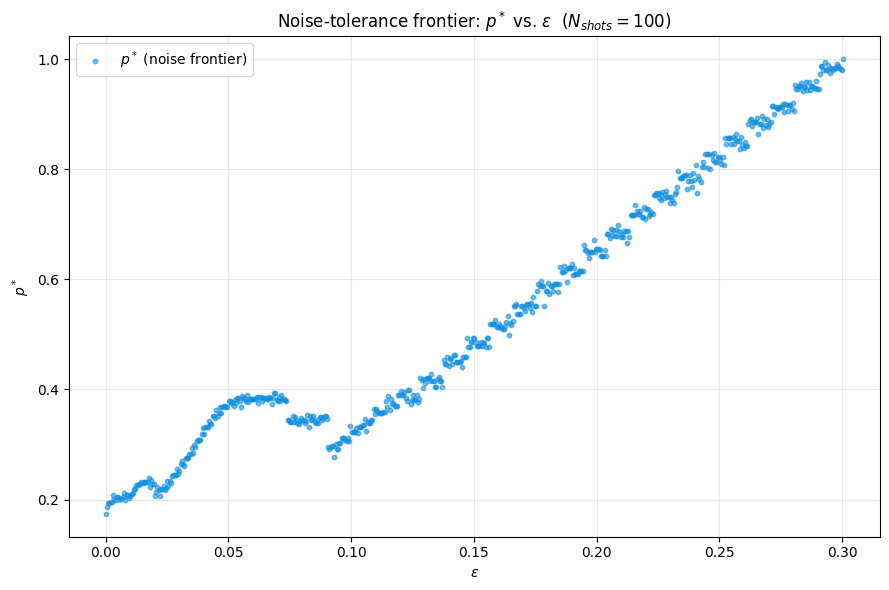

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(epsilon, p_star, color="#1190df", s=10, alpha=0.6,
           label=r"$p^*$ (noise frontier)")

ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$p^*$")
ax.set_title(rf"Noise-tolerance frontier: $p^*$ vs. $\varepsilon$  $(N_{{shots}} = {n_shots})$")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES — imports, problem definition, noise model, N_max
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed

from qiskit.circuit import QuantumCircuit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

# ── Fixed experiment parameters ────────────────────────────────────────────────
p_true = 0.2
ALPHA  = 0.05
N_JOBS = 18


# ── Bernoulli amplitude estimation problem ─────────────────────────────────────
class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)


class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k


problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")


# ── Noise model builder ────────────────────────────────────────────────────────
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

# Physical ceiling for 1-qubit depolarizing_error: λ ∈ [0, 1] is the
# physically meaningful range (λ=1 is full depolarization).
MAX_PHYSICAL_DEPOL = 1.0

def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        p_1q = min(p_depol, MAX_PHYSICAL_DEPOL)
        error_1q = depolarizing_error(p_1q, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler


# ── Ceiling shot budget N_max(eps, alpha) ─────────────────────────────────────
def N_max(epsilon, alpha):
    raw = (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
          * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

print("Prerequisites loaded ✅")

All imports OK ✅
Problem defined ✅
Prerequisites loaded ✅


In [22]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL A
# ══════════════════════════════════════════════════════════════════════════════
def _safe_float(x):
    return float(x) if x is not None else None

def _safe_list(x):
    return list(x) if x is not None else None

def _safe_list_of_lists(x):
    return [list(item) for item in x] if x is not None else None

def _safe_delta_theta_list(theta_intervals):
    """
    Compute Δθ_t = θ_hi - θ_lo for every round t = 1 … T.
    Returns a list of floats (one per round), or None if unavailable.
    Malformed individual rounds are stored as None to preserve indexing.
    """
    if theta_intervals is None or len(theta_intervals) == 0:
        return None
    result = []
    for interval in theta_intervals:
        if interval is not None and len(interval) == 2:
            result.append(float(interval[1] - interval[0]))
        else:
            result.append(None)   # malformed round — keep slot
    return result


def single_diag_run_full(eps, p_noise, n_shots):
    """
    One IQAE run at (eps, p_noise) with shot budget n_shots.
    Captures the full IterativeAmplitudeEstimationResult, excluding
    circuit_results (raw statevector/counts — not needed here).
    Each field is converted defensively so a single None/missing field
    doesn't discard the whole run.
    """
    try:
        sampler = build_noisy_sampler(p_noise, n_shots)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
            confint_method = "beta",  # chernoff or beta (CH or CP)
        )
        result = iae.estimate(problem)

        powers   = list(result.powers) if result.powers is not None else []
        K_values = [2 * k + 1 for k in powers]

        estimate = _safe_float(result.estimation_processed)
        success  = int(estimate is not None and abs(estimate - p_true) <= eps)

        # ── theta intervals — build once, derive delta_theta from it ──────────
        theta_intervals  = _safe_list_of_lists(result.theta_intervals)
        delta_theta_list = _safe_delta_theta_list(theta_intervals)

        return {
            "success"                      : success,
            "powers"                       : powers,
            "K_values"                     : K_values,
            "T_eps"                        : len(powers),
            "max_K"                        : max(K_values) if K_values else None,
            "sum_K"                        : sum(K_values) if K_values else None,

            # amplitude-domain results
            "estimation"                   : estimate,
            "signed_error"                 : (estimate - p_true) if estimate is not None else None,
            "confidence_interval"          : _safe_list(result.confidence_interval),
            "confidence_interval_processed": _safe_list(result.confidence_interval_processed),
            "estimate_intervals"           : _safe_list_of_lists(result.estimate_intervals),

            # angle-domain results
            "theta_intervals"              : theta_intervals,
            "delta_theta_list"             : delta_theta_list,              # [Δθ_1, …, Δθ_T]

            # schedule / information mechanics
            "ratios"                       : _safe_list(result.ratios),
            "num_oracle_queries"           : int(result.num_oracle_queries) if result.num_oracle_queries is not None else None,

            # precision bookkeeping
            "epsilon_target"               : _safe_float(result.epsilon_target),
            "epsilon_estimated"            : _safe_float(result.epsilon_estimated),
            "epsilon_estimated_processed"  : _safe_float(result.epsilon_estimated_processed),
            "alpha_echo"                   : _safe_float(result.alpha),

            # sampling bookkeeping
            "shots"                        : result.shots,
            "n_shots_requested"            : n_shots,

            "error_message"                : None,
        }

    except Exception as e:
        err_str = f"{type(e).__name__}: {e}"
        print(f"[WARN] single_diag_run_full failed: {err_str}")
        return {
            "success": 0, "powers": [], "K_values": [], "T_eps": 0,
            "max_K": None, "sum_K": None,
            "estimation": None, "signed_error": None,
            "confidence_interval": None, "confidence_interval_processed": None,
            "estimate_intervals": None,
            "theta_intervals"              : None,
            "delta_theta_list"             : None,                          # [Δθ_1, …, Δθ_T]
            "ratios": None, "num_oracle_queries": None,
            "epsilon_target": eps, "epsilon_estimated": None,
            "epsilon_estimated_processed": None, "alpha_echo": ALPHA,
            "shots": None, "n_shots_requested": n_shots,
            "error_message": err_str,
        }

In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL B
# ══════════════════════════════════════════════════════════════════════════════

from collections import Counter
from joblib import Parallel, delayed
import numpy as np

N_DIAG = 200   # runs per point

diag_results = []

for eps, p_star_val in zip(epsilon, p_star):
    n_shots_diag = n_shots

    print(f"\n{'─'*60}")
    print(f"ε={eps:.6f} | p*={p_star_val:.6f} | N_shots={n_shots_diag} "
          f"| running {N_DIAG} runs ...")

    runs = Parallel(n_jobs=N_JOBS)(
        delayed(single_diag_run_full)(eps, p_star_val, n_shots_diag)
        for _ in range(N_DIAG)
    )

    # ── Live per-run schedule output ──────────────────────────────────────────
    for i, run in enumerate(runs):
        if run["error_message"] is not None:
            print(f"  run {i+1:>3} | ERROR: {run['error_message']}")
            continue

        status  = "✅" if run["success"] else "❌"
        err_str = f"{run['signed_error']:.6f}" if run["signed_error"] is not None else "N/A"

        # final Δθ — last element of the stored list
        dtl     = run.get("delta_theta_list")
        dth_str = f"{dtl[-1]:.6f}" if (dtl and dtl[-1] is not None) else "N/A"

        print(f"  run {i+1:>3} | {status} | T={run['T_eps']:>2} | "
              f"K_values={run['K_values']} | signed_error={err_str} | "
              f"Δθ_final={dth_str} | Δθ_seq={dtl}")

    # ── Aggregate ─────────────────────────────────────────────────────────────
    valid_runs   = [r for r in runs if r["T_eps"] > 0]
    success_rate = np.mean([r["success"] for r in runs])

    T_values    = [r["T_eps"]  for r in valid_runs]
    maxK_values = [r["max_K"]  for r in valid_runs]
    sumK_values = [r["sum_K"]  for r in valid_runs]
    err_values  = [r["signed_error"] for r in valid_runs
                   if r["signed_error"] is not None]

    # ── delta_theta aggregation — from delta_theta_list ───────────────────────
    # final Δθ per run (last element of each run's list)
    dtheta_final_values = [
        r["delta_theta_list"][-1]
        for r in valid_runs
        if r.get("delta_theta_list") and r["delta_theta_list"][-1] is not None
    ]

    # full Δθ sequences — one list per run (for downstream convergence plots)
    dtheta_sequences = [
        r["delta_theta_list"]
        for r in valid_runs
        if r.get("delta_theta_list") is not None
    ]

    schedule_counts = Counter(tuple(r["K_values"]) for r in valid_runs)
    most_common_schedule, most_common_count = (
        schedule_counts.most_common(1)[0] if schedule_counts else ((), 0)
    )

    diag_results.append({
        "epsilon"              : eps,
        "p_star"               : p_star_val,
        "n_shots"              : n_shots_diag,
        "success_rate"         : success_rate,
        "T_mean"               : float(np.mean(T_values))    if T_values    else None,
        "T_std"                : float(np.std(T_values))     if T_values    else None,
        "max_K_mean"           : float(np.mean(maxK_values)) if maxK_values else None,
        "sum_K_mean"           : float(np.mean(sumK_values)) if sumK_values else None,
        "mean_signed_error"    : float(np.mean(err_values))  if err_values  else None,
        # ── Δθ final (scalar summary) ─────────────────────────────────────────
        "delta_theta_mean"     : float(np.mean(dtheta_final_values))   if dtheta_final_values else None,
        "delta_theta_std"      : float(np.std(dtheta_final_values))    if dtheta_final_values else None,
        "delta_theta_median"   : float(np.median(dtheta_final_values)) if dtheta_final_values else None,
        "n_dtheta_collected"   : len(dtheta_final_values),
        # ── Δθ sequences (full per-round lists) ───────────────────────────────
        "delta_theta_sequences": dtheta_sequences,   # list of lists — one per valid run
        # ─────────────────────────────────────────────────────────────────────
        "most_common_schedule" : list(most_common_schedule),
        "most_common_count"    : most_common_count,
        "n_valid_runs"         : len(valid_runs),
        "raw_runs"             : runs,
    })

    print(f"  → success_rate={success_rate:.3f} | "
          f"Δθ_final mean={diag_results[-1]['delta_theta_mean']:.6f} ± "
          f"{diag_results[-1]['delta_theta_std']:.6f} | "
          f"most_common_schedule={list(most_common_schedule)} "
          f"({most_common_count}/{len(valid_runs)})")

print("\n✅ Full diagnostic sweep complete.")


────────────────────────────────────────────────────────────
ε=0.000100 | p*=0.173828 | N_shots=100 | running 200 runs ...
  run   1 | ✅ | T= 8 | K_values=[1, 1, 1, 5, 19, 79, 371, 1899] | signed_error=-0.000003 | Δθ_final=0.000025 | Δθ_seq=[0.25, 0.04732495103839548, 0.03328227593949978, 0.009428976441191117, 0.0024864688176810673, 0.0005990500131442394, 0.00012704876552398214, 2.4821944957176267e-05]
  run   2 | ✅ | T= 9 | K_values=[1, 1, 1, 1, 7, 21, 99, 489, 2485] | signed_error=-0.000014 | Δθ_final=0.000019 | Δθ_seq=[0.25, 0.047242907535940196, 0.0332208789433915, 0.027061810453702678, 0.00682712623795502, 0.002259473663366679, 0.0004795477978200152, 9.668661793080235e-05, 1.897072953814527e-05]
  run   3 | ❌ | T= 9 | K_values=[1, 1, 1, 1, 7, 27, 123, 595, 3103] | signed_error=0.014719 | Δθ_final=0.000015 | Δθ_seq=[0.25, 0.047181993658732005, 0.03321786770548538, 0.027039218852558777, 0.006810992249151687, 0.0017617162461965458, 0.0003855648714981841, 7.92402091741723e-05, 1.5329

In [24]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL C
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pickle

eps_out              = []
p_star_out           = []
T_out                = []
K_values_out         = []
ratios_out           = []
success_out          = []
n_shots_diag_out     = []
signed_error_out     = []   # per-run signed error        (None if unavailable)
error_message_out    = []   # per-run error message       (None if clean run)
delta_theta_out      = []   # final Δθ per run            (None if unavailable)
delta_theta_list_out = []   # full Δθ sequence per run    (None if unavailable)

# ── Flatten all runs across all epsilon points ────────────────────────────────
for point in diag_results:
    eps_val          = point["epsilon"]
    p_star_val       = point["p_star"]
    n_shots_diag_val = point["n_shots"]

    for run in point["raw_runs"]:
        eps_out.append(eps_val)
        p_star_out.append(p_star_val)
        T_out.append(run["T_eps"])
        K_values_out.append(run["K_values"])
        ratios_out.append(run["ratios"])
        success_out.append(bool(run["success"]))
        n_shots_diag_out.append(n_shots_diag_val)
        signed_error_out.append(run.get("signed_error"))       # None if errored
        error_message_out.append(run.get("error_message"))     # None if clean

        # ── Δθ — read directly from Cell A's stored list ─────────────────────
        dtl = run.get("delta_theta_list")
        delta_theta_list_out.append(dtl)                       # full sequence or None
        delta_theta_out.append(
            dtl[-1] if (dtl and dtl[-1] is not None) else None # final value  or None
        )

# ── Convert to numpy arrays ───────────────────────────────────────────────────
eps_arr              = np.array(eps_out)
p_star_arr           = np.array(p_star_out)
T_arr                = np.array(T_out)
K_values_arr         = np.array(K_values_out,        dtype=object)  # ragged
ratios_arr           = np.array(ratios_out,           dtype=object)  # ragged
success_arr          = np.array(success_out,          dtype=bool)
n_shots_diag_arr     = np.array(n_shots_diag_out,     dtype=int)
signed_error_arr     = np.array(signed_error_out,     dtype=object)  # float or None
error_message_arr    = np.array(error_message_out,    dtype=object)  # str   or None
delta_theta_arr      = np.array(delta_theta_out,      dtype=object)  # float or None
delta_theta_list_arr = np.array(delta_theta_list_out, dtype=object)  # list  or None

# ── Summary printout ──────────────────────────────────────────────────────────
n_total      = len(eps_arr)
n_errored    = int(np.sum([m is not None for m in error_message_out]))
n_success    = int(np.sum(success_arr))
n_fail_clean = int(np.sum(~success_arr)) - n_errored
n_dtheta     = int(np.sum([v is not None for v in delta_theta_out]))
n_dtheta_seq = int(np.sum([v is not None for v in delta_theta_list_out]))

print(f"Exported {n_total} run records across {len(diag_results)} epsilon points.")
print(f"  Failed runs (error_message set)  : {n_errored}")
print(f"  Successful runs                  : {n_success}")
print(f"  Failed (no error, just ❌)       : {n_fail_clean}")
print(f"  Runs with valid Δθ final         : {n_dtheta}     / {n_total}")
print(f"  Runs with valid Δθ sequence      : {n_dtheta_seq} / {n_total}")

# ── Save to disk ──────────────────────────────────────────────────────────────
np.savez(
    "iqae_shots100_2.npz",
    epsilon          = eps_arr,
    p_star           = p_star_arr,
    T                = T_arr,
    K_values         = K_values_arr,
    ratios           = ratios_arr,
    success          = success_arr,
    n_shots_diag     = n_shots_diag_arr,
    signed_error     = signed_error_arr,
    error_message    = error_message_arr,
    delta_theta      = delta_theta_arr,        # scalar final Δθ per run
    delta_theta_list = delta_theta_list_arr,   # full [Δθ_1, …, Δθ_T] per run
    allow_pickle     = True,
)

print("✅ Saved to iqae_shots100.npz")

Exported 120200 run records across 601 epsilon points.
  Failed runs (error_message set)  : 0
  Successful runs                  : 60344
  Failed (no error, just ❌)       : 59856
  Runs with valid Δθ final         : 120200     / 120200
  Runs with valid Δθ sequence      : 120200 / 120200
✅ Saved to iqae_shots100.npz


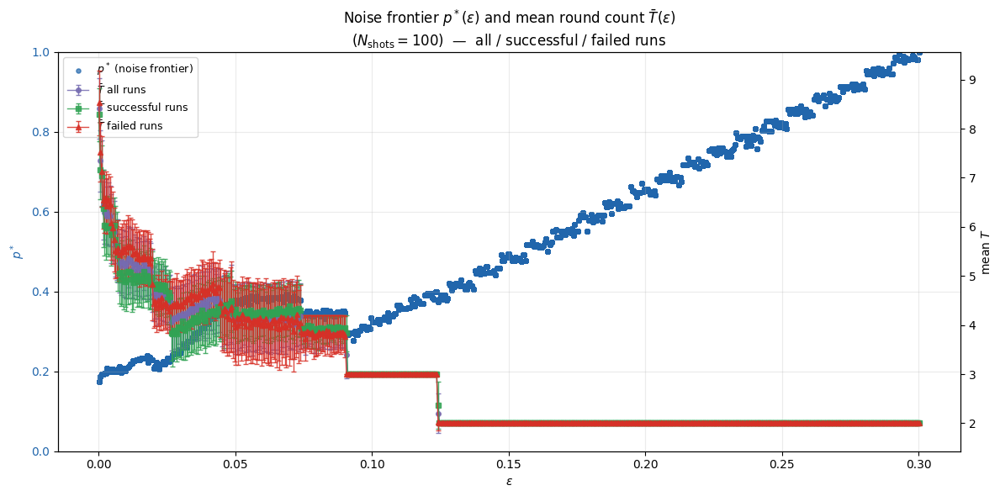

In [25]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL D — Plot: epsilon vs p_star, and mean T (all / successful / failed runs)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np

data = np.load("iqae_shots100_2.npz", allow_pickle=True)
eps_arr          = data["epsilon"]
p_star_arr       = data["p_star"]
T_arr            = data["T"]
K_values_arr     = data["K_values"]
ratios_arr       = data["ratios"]
success_arr      = data["success"]
n_shots_diag_arr = data["n_shots_diag"]
delta_theta_arr = data["delta_theta"]

# ── Aggregate T per unique epsilon, three slices ─────────────────────────────
unique_eps = np.unique(eps_arr)

eps_agg_all  = [];  T_all_mean  = [];  T_all_std  = []
eps_agg_succ = [];  T_succ_mean = [];  T_succ_std = []
eps_agg_fail = [];  T_fail_mean = [];  T_fail_std = []

n_omitted_succ = 0
n_omitted_fail = 0

for eps_val in unique_eps:
    mask_all  = (eps_arr == eps_val)
    mask_succ = mask_all & success_arr
    mask_fail = mask_all & ~success_arr

    # ── all runs ──────────────────────────────────────────────────────────────
    if np.any(mask_all):
        eps_agg_all.append(eps_val)
        T_all_mean.append(T_arr[mask_all].mean())
        T_all_std.append(T_arr[mask_all].std())

    # ── successful runs only ──────────────────────────────────────────────────
    if np.any(mask_succ):
        eps_agg_succ.append(eps_val)
        T_succ_mean.append(T_arr[mask_succ].mean())
        T_succ_std.append(T_arr[mask_succ].std())
    else:
        n_omitted_succ += 1

    # ── failed runs only ──────────────────────────────────────────────────────
    if np.any(mask_fail):
        eps_agg_fail.append(eps_val)
        T_fail_mean.append(T_arr[mask_fail].mean())
        T_fail_std.append(T_arr[mask_fail].std())
    else:
        n_omitted_fail += 1

eps_agg_all  = np.array(eps_agg_all);   T_all_mean  = np.array(T_all_mean);   T_all_std  = np.array(T_all_std)
eps_agg_succ = np.array(eps_agg_succ);  T_succ_mean = np.array(T_succ_mean);  T_succ_std = np.array(T_succ_std)
eps_agg_fail = np.array(eps_agg_fail);  T_fail_mean = np.array(T_fail_mean);  T_fail_std = np.array(T_fail_std)

if n_omitted_succ:
    print(f"⚠ {n_omitted_succ} epsilon points had 0 successful runs — omitted from success T line")
if n_omitted_fail:
    print(f"⚠ {n_omitted_fail} epsilon points had 0 failed runs — omitted from fail T line")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(12, 6))

# ── Left axis: p_star ─────────────────────────────────────────────────────────
color_p = "#2166ac"
ax1.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.7,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)

# ── Right axis: three T lines ─────────────────────────────────────────────────
ax2 = ax1.twinx()

color_all  = "#756bb1"   # purple  — all runs
color_succ = "#31a354"   # green   — successful
color_fail = "#d73027"   # red     — failed

ax2.errorbar(eps_agg_all,  T_all_mean,  yerr=T_all_std,
             fmt="o-",  color=color_all,  markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{T}$ all runs")

ax2.errorbar(eps_agg_succ, T_succ_mean, yerr=T_succ_std,
             fmt="s-",  color=color_succ, markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{T}$ successful runs")

ax2.errorbar(eps_agg_fail, T_fail_mean, yerr=T_fail_std,
             fmt="^-",  color=color_fail, markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{T}$ failed runs")

ax2.set_ylabel(r"mean $T$", color="black")
ax2.tick_params(axis="y", labelcolor="black")

ax1.set_title(
    r"Noise frontier $p^*(\varepsilon)$ and mean round count $\bar{T}(\varepsilon)$"
    "\n"
    r"$(N_{\mathrm{shots}} = 100)$  —  all / successful / failed runs"
)
ax1.grid(True, alpha=0.25)

# ── Combined legend ───────────────────────────────────────────────────────────
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

In [26]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL E (v4) — Fixed-shot (N_shots=100): Cliff window + three-slice T
#               aggregation (all / successful / failed)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.lines import Line2D

# ── Load data ─────────────────────────────────────────────────────────────────
data = np.load("iqae_shots100.npz", allow_pickle=True)
eps_arr     = data["epsilon"]
p_star_arr  = data["p_star"]
T_arr       = data["T"]
K_values_arr = data["K_values"]
ratios_arr  = data["ratios"]
success_arr = data["success"]

N_SHOTS_FIXED = 100   # label only — baked into the file

# ── Reconstruct sorted unique frontier ───────────────────────────────────────
unique_eps_frontier, first_occ = np.unique(eps_arr, return_index=True)
p_star_frontier                = p_star_arr[first_occ]

sort_idx            = np.argsort(unique_eps_frontier)
eps_front_sorted    = unique_eps_frontier[sort_idx]
p_star_front_sorted = p_star_frontier[sort_idx]

# ── Three-slice T aggregation ─────────────────────────────────────────────────
unique_eps = np.unique(eps_arr)

eps_agg_all  = [];  T_all_mean  = [];  T_all_std  = []
eps_agg_succ = [];  T_succ_mean = [];  T_succ_std = []
eps_agg_fail = [];  T_fail_mean = [];  T_fail_std = []

n_omitted_succ = 0
n_omitted_fail = 0

for eps_val in unique_eps:
    mask_all  = (eps_arr == eps_val)
    mask_succ = mask_all &  success_arr
    mask_fail = mask_all & ~success_arr

    # all runs
    if np.any(mask_all):
        eps_agg_all.append(eps_val)
        T_all_mean.append(T_arr[mask_all].mean())
        T_all_std.append(T_arr[mask_all].std())

    # successful runs only
    if np.any(mask_succ):
        eps_agg_succ.append(eps_val)
        T_succ_mean.append(T_arr[mask_succ].mean())
        T_succ_std.append(T_arr[mask_succ].std())
    else:
        n_omitted_succ += 1

    # failed runs only
    if np.any(mask_fail):
        eps_agg_fail.append(eps_val)
        T_fail_mean.append(T_arr[mask_fail].mean())
        T_fail_std.append(T_arr[mask_fail].std())
    else:
        n_omitted_fail += 1

eps_agg_all  = np.array(eps_agg_all);   T_all_mean  = np.array(T_all_mean);   T_all_std  = np.array(T_all_std)
eps_agg_succ = np.array(eps_agg_succ);  T_succ_mean = np.array(T_succ_mean);  T_succ_std = np.array(T_succ_std)
eps_agg_fail = np.array(eps_agg_fail);  T_fail_mean = np.array(T_fail_mean);  T_fail_std = np.array(T_fail_std)

if n_omitted_succ:
    print(f"⚠ {n_omitted_succ} epsilon points had 0 successful runs  — omitted from success T line")
if n_omitted_fail:
    print(f"⚠ {n_omitted_fail} epsilon points had 0 failed runs      — omitted from fail T line")

# ── Find dominant cliff ───────────────────────────────────────────────────────
dp        = np.diff(p_star_front_sorted)
cliff_idx = np.argmin(dp)

eps_before    = eps_front_sorted[cliff_idx]
p_star_before = p_star_front_sorted[cliff_idx]
eps_after     = eps_front_sorted[cliff_idx + 1]
p_star_after  = p_star_front_sorted[cliff_idx + 1]

print(f"Dominant cliff:")
print(f"  BEFORE: ε={eps_before:.6f}  p*={p_star_before:.6f}")
print(f"  AFTER:  ε={eps_after:.6f}  p*={p_star_after:.6f}")

# ── Extract window ────────────────────────────────────────────────────────────
N_WINDOW = 6

window_start = max(0, cliff_idx - N_WINDOW)
window_end   = min(len(eps_front_sorted) - 1, cliff_idx + N_WINDOW + 1)

window_eps   = eps_front_sorted[window_start : window_end + 1]
window_pstar = p_star_front_sorted[window_start : window_end + 1]

# ── Print window table ────────────────────────────────────────────────────────
print("=" * 90)
print(f"  {'idx':>4}  {'ε':>10}  {'p*':>8}  {'Δp*':>8}  "
      f"{'T_dist':<35}  {'SR':>6}  zone")
print(f"  {'─'*4}  {'─'*10}  {'─'*8}  {'─'*8}  "
      f"{'─'*35}  {'─'*6}  {'─'*15}")

cliff_window_points = []

for i, (eps_val, pstar_val) in enumerate(zip(window_eps, window_pstar)):
    global_idx = window_start + i

    delta_p = (p_star_front_sorted[global_idx] -
               p_star_front_sorted[global_idx - 1]
               if global_idx > 0 else 0.0)

    mask     = (eps_arr == eps_val)
    T_here   = T_arr[mask]
    S_here   = success_arr[mask]
    T_counts = Counter(T_here.tolist())
    sr       = float(S_here.mean())
    T_str    = "  ".join(f"T={t}:{T_counts[t]:>3}" for t in sorted(T_counts))
    is_mixed = len(T_counts) > 1

    if global_idx < cliff_idx:
        zone = "pre-cliff"
    elif global_idx == cliff_idx:
        zone = "◀ BEFORE"
    elif global_idx == cliff_idx + 1:
        zone = "AFTER ▶"
    else:
        zone = "post-cliff"

    if is_mixed:
        zone += " ⚡MIXED"

    print(f"  {global_idx:>4}  {eps_val:>10.6f}  {pstar_val:>8.4f}  "
          f"{delta_p:>+8.4f}  {T_str:<35}  {sr:>6.3f}  {zone}")

    cliff_window_points.append({
        "global_idx"  : global_idx,
        "epsilon"     : eps_val,
        "p_star"      : pstar_val,
        "delta_p"     : delta_p,
        "T_counts"    : T_counts,
        "success_rate": sr,
        "is_before"   : global_idx == cliff_idx,
        "is_after"    : global_idx == cliff_idx + 1,
        "is_mixed"    : is_mixed,
    })

print("=" * 90)

# ── Summary ───────────────────────────────────────────────────────────────────
mixed_pts = [p for p in cliff_window_points if p["is_mixed"]]
pure_T3   = [p for p in cliff_window_points
             if not p["is_mixed"] and 3 in p["T_counts"] and 2 not in p["T_counts"]]
pure_T2   = [p for p in cliff_window_points
             if not p["is_mixed"] and 2 in p["T_counts"] and 3 not in p["T_counts"]]

print(f"\n  Pure T=3 points in window : {len(pure_T3)}")
print(f"  Mixed T=2/3 points        : {len(mixed_pts)}")
print(f"  Pure T=2 points in window : {len(pure_T2)}")
if mixed_pts:
    mixed_eps_str = ", ".join(f"{p['epsilon']:.6f}" for p in mixed_pts)
    print(f"  Mixed epsilon values      : {mixed_eps_str}")

# ══════════════════════════════════════════════════════════════════════════════
# Plot
# ══════════════════════════════════════════════════════════════════════════════
fig, ax1 = plt.subplots(figsize=(12, 6))

# ── Left axis: p_star ─────────────────────────────────────────────────────────
color_p = "#2166ac"
ax1.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.5,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)

# ── Right axis: three T slices ────────────────────────────────────────────────
ax2 = ax1.twinx()

color_all  = "#756bb1"   # purple — all runs
color_succ = "#31a354"   # green  — successful
color_fail = "#d73027"   # red    — failed

ax2.errorbar(eps_agg_all,  T_all_mean,  yerr=T_all_std,
             fmt="o-",  color=color_all,  markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{T}$ all runs")

ax2.errorbar(eps_agg_succ, T_succ_mean, yerr=T_succ_std,
             fmt="s-",  color=color_succ, markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{T}$ successful runs")

ax2.errorbar(eps_agg_fail, T_fail_mean, yerr=T_fail_std,
             fmt="^-",  color=color_fail, markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{T}$ failed runs")

ax2.set_ylabel(r"mean $T$", color="black")
ax2.tick_params(axis="y", labelcolor="black")

# ── Colour-code window points on left axis ────────────────────────────────────
for pt in cliff_window_points:
    if pt["is_before"]:
        col, mk, sz = "darkorange", "*", 220
    elif pt["is_after"]:
        col, mk, sz = "darkgreen",  "*", 220
    elif pt["is_mixed"]:
        col, mk, sz = "red",        "D", 110
    else:
        col, mk, sz = "purple",     "o",  70

    ax1.scatter(pt["epsilon"], pt["p_star"],
                color=col, marker=mk, s=sz, zorder=5)

    ax1.annotate(
        f"ε={pt['epsilon']:.5f}\n"
        f"p*={pt['p_star']:.4f}",
        xy=(pt["epsilon"], pt["p_star"]),
        xytext=(pt["epsilon"], pt["p_star"] + 0.05),
        fontsize=6, color=col, ha="center",
        arrowprops=dict(arrowstyle="-", color=col, lw=0.8),
    )

# ── Shade mixed zone ──────────────────────────────────────────────────────────
if mixed_pts:
    mx_lo = min(p["epsilon"] for p in mixed_pts) - 0.0005
    mx_hi = max(p["epsilon"] for p in mixed_pts) + 0.0005
    ax1.axvspan(mx_lo, mx_hi, alpha=0.15, color="red",
                label="Mixed T=2/3 zone")

# ── Combined legend ───────────────────────────────────────────────────────────
custom_handles = [
    Line2D([0],[0], marker="*", color="darkorange", ms=11, ls="none",
           label=rf"BEFORE ($\varepsilon={eps_before:.5f}$)"),
    Line2D([0],[0], marker="*", color="darkgreen",  ms=11, ls="none",
           label=rf"AFTER  ($\varepsilon={eps_after:.5f}$)"),
    Line2D([0],[0], marker="D", color="red",        ms=8,  ls="none",
           label="Mixed T=2/3"),
    Line2D([0],[0], marker="o", color="purple",     ms=7,  ls="none",
           label="Window (pure)"),
]

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    custom_handles + lines2,
    [h.get_label() for h in custom_handles] + labels2,
    loc="upper left", fontsize=8
)

ax1.set_title(
    r"Cliff transition window — $p^*$ drop + $\bar{T}$ (all / successful / failed)"
    "\n"
    rf"BEFORE $\varepsilon={eps_before:.5f}$,  "
    rf"AFTER $\varepsilon={eps_after:.5f}$  "
    rf"(window = $\pm${N_WINDOW} points,  $N_{{\mathrm{{shots}}}}={N_SHOT   S_FIXED}$)"
)
ax1.grid(True, alpha=0.25)
ax1.set_xlim(window_eps[0] - 0.001, window_eps[-1] + 0.0003)

plt.tight_layout()
plt.show()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2252614763.py, line 256)

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_29464\1646127387.py:159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


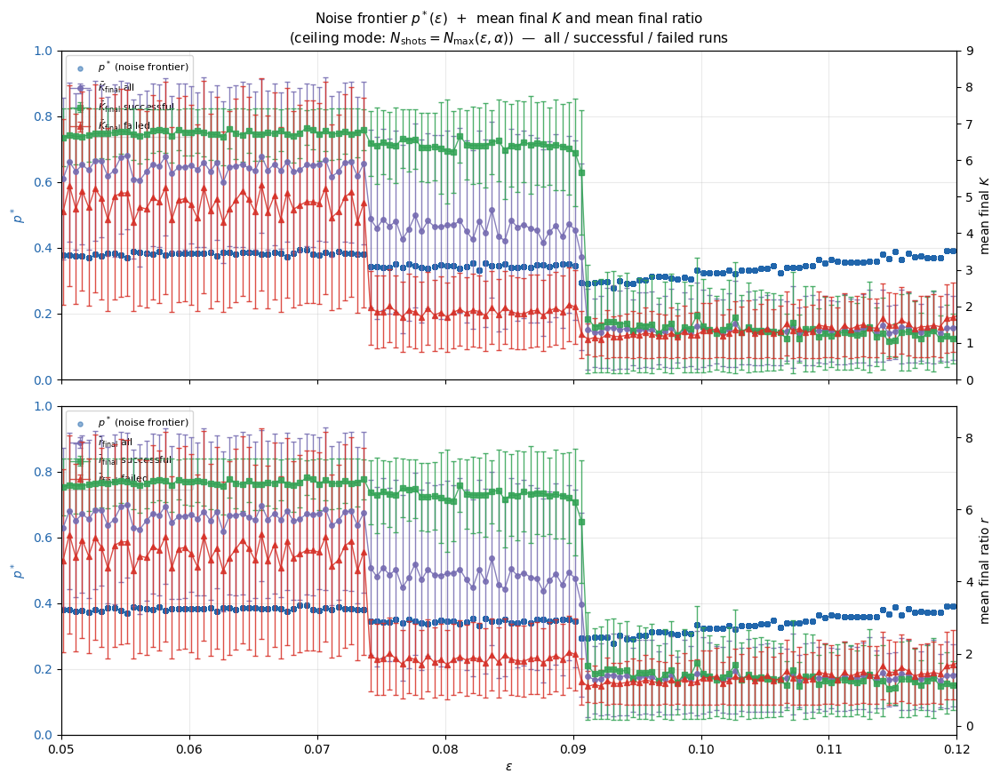

In [27]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL D2 — Plot: epsilon vs p_star  +  final K  +  final ratio
#            (all / successful / failed),  three right-hand axes
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np

# ── file is already open; eps_arr, p_star_arr, K_values_arr, ratios_arr,
#    success_arr are already in scope from Cell D ────────────────────────────

# ── Aggregate per unique epsilon ──────────────────────────────────────────────
unique_eps = np.unique(eps_arr)

# containers — K (final value)
eps_K_all  = [];  K_all_mean  = [];  K_all_std  = []
eps_K_succ = [];  K_succ_mean = [];  K_succ_std = []
eps_K_fail = [];  K_fail_mean = [];  K_fail_std = []

# containers — ratio (final value)
eps_R_all  = [];  R_all_mean  = [];  R_all_std  = []
eps_R_succ = [];  R_succ_mean = [];  R_succ_std = []
eps_R_fail = [];  R_fail_mean = [];  R_fail_std = []

n_omitted_K_succ = 0;  n_omitted_K_fail = 0
n_omitted_R_succ = 0;  n_omitted_R_fail = 0

for eps_val in unique_eps:
    mask_all  = (eps_arr == eps_val)
    mask_succ = mask_all &  success_arr
    mask_fail = mask_all & ~success_arr

    # ── extract final K and final ratio for every run at this epsilon ─────────
    # K_values_arr and ratios_arr are object arrays of variable-length arrays;
    # "final" = last element of each inner array
    K_final_all = np.array([arr[-1] for arr in K_values_arr[mask_all]])
    R_final_all = np.array([arr[-1] for arr in ratios_arr[mask_all]])

    # ── all runs ──────────────────────────────────────────────────────────────
    if len(K_final_all):
        eps_K_all.append(eps_val);  K_all_mean.append(K_final_all.mean());  K_all_std.append(K_final_all.std())
        eps_R_all.append(eps_val);  R_all_mean.append(R_final_all.mean());  R_all_std.append(R_final_all.std())

    # ── successful runs ───────────────────────────────────────────────────────
    if np.any(mask_succ):
        K_final_succ = np.array([arr[-1] for arr in K_values_arr[mask_succ]])
        R_final_succ = np.array([arr[-1] for arr in ratios_arr[mask_succ]])
        eps_K_succ.append(eps_val);  K_succ_mean.append(K_final_succ.mean());  K_succ_std.append(K_final_succ.std())
        eps_R_succ.append(eps_val);  R_succ_mean.append(R_final_succ.mean());  R_succ_std.append(R_final_succ.std())
    else:
        n_omitted_K_succ += 1
        n_omitted_R_succ += 1

    # ── failed runs ───────────────────────────────────────────────────────────
    if np.any(mask_fail):
        K_final_fail = np.array([arr[-1] for arr in K_values_arr[mask_fail]])
        R_final_fail = np.array([arr[-1] for arr in ratios_arr[mask_fail]])
        eps_K_fail.append(eps_val);  K_fail_mean.append(K_final_fail.mean());  K_fail_std.append(K_final_fail.std())
        eps_R_fail.append(eps_val);  R_fail_mean.append(R_final_fail.mean());  R_fail_std.append(R_final_fail.std())
    else:
        n_omitted_K_fail += 1
        n_omitted_R_fail += 1

# convert to arrays
eps_K_all  = np.array(eps_K_all);   K_all_mean  = np.array(K_all_mean);   K_all_std  = np.array(K_all_std)
eps_K_succ = np.array(eps_K_succ);  K_succ_mean = np.array(K_succ_mean);  K_succ_std = np.array(K_succ_std)
eps_K_fail = np.array(eps_K_fail);  K_fail_mean = np.array(K_fail_mean);  K_fail_std = np.array(K_fail_std)

eps_R_all  = np.array(eps_R_all);   R_all_mean  = np.array(R_all_mean);   R_all_std  = np.array(R_all_std)
eps_R_succ = np.array(eps_R_succ);  R_succ_mean = np.array(R_succ_mean);  R_succ_std = np.array(R_succ_std)
eps_R_fail = np.array(eps_R_fail);  R_fail_mean = np.array(R_fail_mean);  R_fail_std = np.array(R_fail_std)

# ── warnings ──────────────────────────────────────────────────────────────────
if n_omitted_K_succ: print(f"⚠ final-K : {n_omitted_K_succ} ε points had 0 successful runs — omitted")
if n_omitted_K_fail: print(f"⚠ final-K : {n_omitted_K_fail} ε points had 0 failed runs     — omitted")
if n_omitted_R_succ: print(f"⚠ ratio   : {n_omitted_R_succ} ε points had 0 successful runs — omitted")
if n_omitted_R_fail: print(f"⚠ ratio   : {n_omitted_R_fail} ε points had 0 failed runs     — omitted")

# ══════════════════════════════════════════════════════════════════════════════
# Figure — two stacked subplots sharing the x-axis
#   top    : p*  +  final K  (dual y)
#   bottom : p*  +  final ratio  (dual y)
# ══════════════════════════════════════════════════════════════════════════════
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(13, 10), sharex=True,
    gridspec_kw={"hspace": 0.08}
)

color_p    = "#2166ac"   # blue   — p*
color_all  = "#756bb1"   # purple — all runs
color_succ = "#31a354"   # green  — successful
color_fail = "#d73027"   # red    — failed

# ─────────────────────────────────────────────────────────────────────────────
# TOP subplot — p*  +  final K
# ─────────────────────────────────────────────────────────────────────────────
ax_top.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.5,
               label=r"$p^*$ (noise frontier)")
ax_top.set_ylabel(r"$p^*$", color=color_p)
ax_top.tick_params(axis="y", labelcolor=color_p)
ax_top.set_ylim(0, 1)
ax_top.grid(True, alpha=0.25)

ax_K = ax_top.twinx()
ax_K.errorbar(eps_K_all,  K_all_mean,  yerr=K_all_std,
              fmt="o-",  color=color_all,  markersize=4, linewidth=1,
              capsize=2, alpha=0.85, label=r"$\bar{K}_{\mathrm{final}}$ all")
ax_K.errorbar(eps_K_succ, K_succ_mean, yerr=K_succ_std,
              fmt="s-",  color=color_succ, markersize=4, linewidth=1,
              capsize=2, alpha=0.85, label=r"$\bar{K}_{\mathrm{final}}$ successful")
ax_K.errorbar(eps_K_fail, K_fail_mean, yerr=K_fail_std,
              fmt="^-",  color=color_fail, markersize=4, linewidth=1,
              capsize=2, alpha=0.85, label=r"$\bar{K}_{\mathrm{final}}$ failed")
ax_K.set_ylabel(r"mean final $K$", color="black")
ax_K.tick_params(axis="y", labelcolor="black")
ax_K.set_ylim(0, 9)

# combined legend — top
l1, b1 = ax_top.get_legend_handles_labels()
l2, b2 = ax_K.get_legend_handles_labels()
ax_top.legend(l1 + l2, b1 + b2, loc="upper left", fontsize=8)
ax_top.set_title(
    r"Noise frontier $p^*(\varepsilon)$  +  mean final $K$ and mean final ratio"
    "\n"
    r"(ceiling mode: $N_{\mathrm{shots}} = N_{\max}(\varepsilon,\alpha)$)"
    "  —  all / successful / failed runs",
    fontsize=11
)

# ─────────────────────────────────────────────────────────────────────────────
# BOTTOM subplot — p*  +  final ratio
# ─────────────────────────────────────────────────────────────────────────────
ax_bot.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.5,
               label=r"$p^*$ (noise frontier)")
ax_bot.set_xlabel(r"$\varepsilon$")
ax_bot.set_ylabel(r"$p^*$", color=color_p)
ax_bot.tick_params(axis="y", labelcolor=color_p)
ax_bot.set_ylim(0, 1)
ax_bot.grid(True, alpha=0.25)

ax_R = ax_bot.twinx()
ax_R.errorbar(eps_R_all,  R_all_mean,  yerr=R_all_std,
              fmt="o-",  color=color_all,  markersize=4, linewidth=1,
              capsize=2, alpha=0.85, label=r"$\bar{r}_{\mathrm{final}}$ all")
ax_R.errorbar(eps_R_succ, R_succ_mean, yerr=R_succ_std,
              fmt="s-",  color=color_succ, markersize=4, linewidth=1,
              capsize=2, alpha=0.85, label=r"$\bar{r}_{\mathrm{final}}$ successful")
ax_R.errorbar(eps_R_fail, R_fail_mean, yerr=R_fail_std,
              fmt="^-",  color=color_fail, markersize=4, linewidth=1,
              capsize=2, alpha=0.85, label=r"$\bar{r}_{\mathrm{final}}$ failed")
ax_R.set_ylabel(r"mean final ratio $r$", color="black")
ax_R.tick_params(axis="y", labelcolor="black")

# combined legend — bottom
l3, b3 = ax_bot.get_legend_handles_labels()
l4, b4 = ax_R.get_legend_handles_labels()
ax_bot.legend(l3 + l4, b3 + b4, loc="upper left", fontsize=8)
ax_top.set_xlim(0.05, 0.12)
plt.tight_layout()
plt.show()

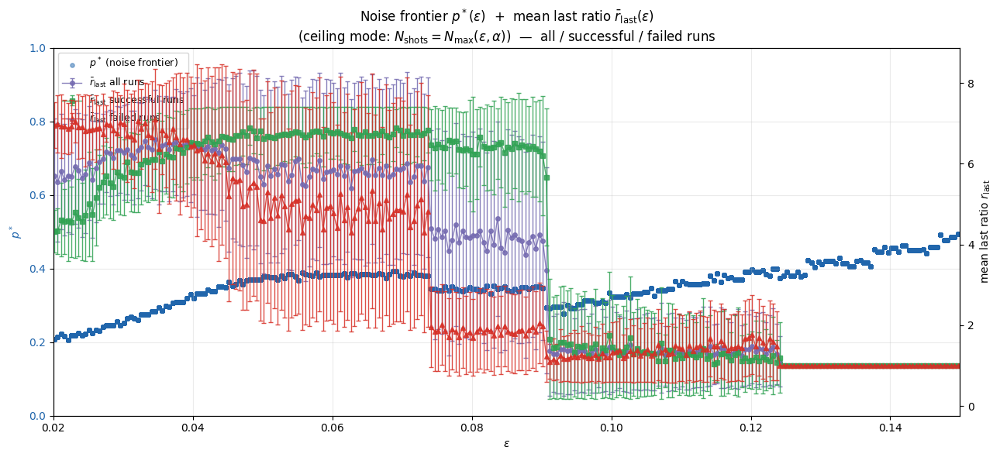

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL D3 — Plot: epsilon vs p_star  +  mean LAST ratio only
#            (all / successful / failed runs)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np

# ── file already open; eps_arr, p_star_arr, ratios_arr, success_arr in scope ─

# ── X-axis zoom — adjust manually ────────────────────────────────────────────
X_LIM_LO = 0.02    # ← set e.g. 0.01 to zoom in
X_LIM_HI = 0.15    # ← set e.g. 0.10 to zoom in

# ── Aggregate last ratio per unique epsilon, three slices ─────────────────────
unique_eps = np.unique(eps_arr)

eps_R_all  = [];  R_all_mean  = [];  R_all_std  = []
eps_R_succ = [];  R_succ_mean = [];  R_succ_std = []
eps_R_fail = [];  R_fail_mean = [];  R_fail_std = []

n_omitted_succ = 0
n_omitted_fail = 0

for eps_val in unique_eps:
    mask_all  = (eps_arr == eps_val)
    mask_succ = mask_all &  success_arr
    mask_fail = mask_all & ~success_arr

    # ── last ratio for every run at this epsilon ──────────────────────────────
    R_last_all = np.array([arr[-1] for arr in ratios_arr[mask_all]])

    # ── all runs ──────────────────────────────────────────────────────────────
    if len(R_last_all):
        eps_R_all.append(eps_val)
        R_all_mean.append(R_last_all.mean())
        R_all_std.append(R_last_all.std())

    # ── successful runs ───────────────────────────────────────────────────────
    if np.any(mask_succ):
        R_last_succ = np.array([arr[-1] for arr in ratios_arr[mask_succ]])
        eps_R_succ.append(eps_val)
        R_succ_mean.append(R_last_succ.mean())
        R_succ_std.append(R_last_succ.std())
    else:
        n_omitted_succ += 1

    # ── failed runs ───────────────────────────────────────────────────────────
    if np.any(mask_fail):
        R_last_fail = np.array([arr[-1] for arr in ratios_arr[mask_fail]])
        eps_R_fail.append(eps_val)
        R_fail_mean.append(R_last_fail.mean())
        R_fail_std.append(R_last_fail.std())
    else:
        n_omitted_fail += 1

eps_R_all  = np.array(eps_R_all);   R_all_mean  = np.array(R_all_mean);   R_all_std  = np.array(R_all_std)
eps_R_succ = np.array(eps_R_succ);  R_succ_mean = np.array(R_succ_mean);  R_succ_std = np.array(R_succ_std)
eps_R_fail = np.array(eps_R_fail);  R_fail_mean = np.array(R_fail_mean);  R_fail_std = np.array(R_fail_std)

if n_omitted_succ:
    print(f"⚠ {n_omitted_succ} ε points had 0 successful runs — omitted from success line")
if n_omitted_fail:
    print(f"⚠ {n_omitted_fail} ε points had 0 failed runs     — omitted from fail line")

# ══════════════════════════════════════════════════════════════════════════════
# Plot
# ══════════════════════════════════════════════════════════════════════════════
fig, ax1 = plt.subplots(figsize=(13, 6))

color_p    = "#2166ac"   # blue   — p*
color_all  = "#756bb1"   # purple — all runs
color_succ = "#31a354"   # green  — successful
color_fail = "#d73027"   # red    — failed

# ── Left axis: p_star ─────────────────────────────────────────────────────────
ax1.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.5,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)
ax1.grid(True, alpha=0.25)

# ── Right axis: mean last ratio ───────────────────────────────────────────────
ax2 = ax1.twinx()

ax2.errorbar(eps_R_all,  R_all_mean,  yerr=R_all_std,
             fmt="o-",  color=color_all,  markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{r}_{\mathrm{last}}$ all runs")

ax2.errorbar(eps_R_succ, R_succ_mean, yerr=R_succ_std,
             fmt="s-",  color=color_succ, markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{r}_{\mathrm{last}}$ successful runs")

ax2.errorbar(eps_R_fail, R_fail_mean, yerr=R_fail_std,
             fmt="^-",  color=color_fail, markersize=4, linewidth=1,
             capsize=2, alpha=0.85, label=r"$\bar{r}_{\mathrm{last}}$ failed runs")

ax2.set_ylabel(r"mean last ratio $r_{\mathrm{last}}$", color="black")
ax2.tick_params(axis="y", labelcolor="black")

# ── Combined legend ───────────────────────────────────────────────────────────
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

ax1.set_title(
    r"Noise frontier $p^*(\varepsilon)$  +  mean last ratio $\bar{r}_{\mathrm{last}}(\varepsilon)$"
    "\n"
    r"(ceiling mode: $N_{\mathrm{shots}} = N_{\max}(\varepsilon,\alpha)$)"
    "  —  all / successful / failed runs"
)

# ── X-axis zoom ───────────────────────────────────────────────────────────────
if X_LIM_LO is not None or X_LIM_HI is not None:
    ax1.set_xlim(X_LIM_LO, X_LIM_HI)

plt.tight_layout()
plt.show()

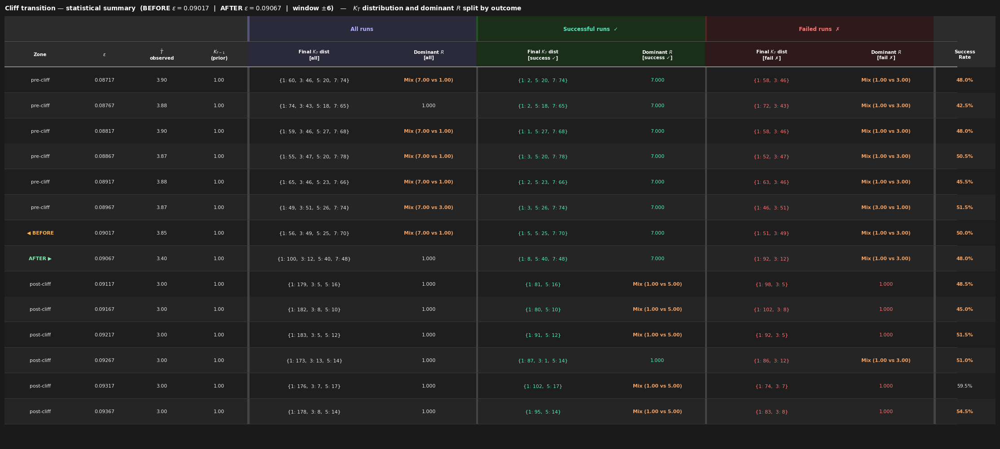

In [29]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL — Cliff statistical summary table  (with success / fail split columns)
#         Computed entirely from data — no hardcoded values
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from collections import Counter
import numpy as np

# ── Genuine mixed threshold (mirror Cell E) ───────────────────────────────────
MIXED_MIN_FRAC = 0.10

def is_genuine_mixed(counts: Counter) -> bool:
    if len(counts) < 2:
        return False
    total = sum(counts.values())
    return all(c / total >= MIXED_MIN_FRAC for c in counts.values())

def dominant_R_str(K_values_slice):
    """Return (R_string, is_mixture) for a slice of K_values arrays."""
    if len(K_values_slice) == 0:
        return "—", False
    R_vals = np.array([
        arr[-1] / (arr[-2] if len(arr) >= 2 else arr[-1])
        for arr in K_values_slice
    ])
    R_counts = Counter(np.round(R_vals, 4).tolist())
    if is_genuine_mixed(R_counts):
        top2  = sorted(R_counts.items(), key=lambda x: -x[1])[:2]
        return "Mix (" + " vs ".join(f"{r:.2f}" for r, _ in top2) + ")", True
    dominant = max(R_counts, key=R_counts.get)
    return f"{dominant:.3f}", False

def K_dist_str(K_values_slice):
    """Return '{k: count, ...}' string for final K of a slice."""
    if len(K_values_slice) == 0:
        return "—"
    finals = [arr[-1] for arr in K_values_slice]
    counts = Counter(finals)
    return "{" + ",  ".join(
        f"{int(k)}: {v}" for k, v in sorted(counts.items())
    ) + "}"

# ══════════════════════════════════════════════════════════════════════════════
# Build summary rows
# ══════════════════════════════════════════════════════════════════════════════
def build_summary_rows(cliff_window_points, eps_arr, T_arr,
                       K_values_arr, ratios_arr, success_arr, cliff_idx):
    rows = []
    for pt in cliff_window_points:
        eps_val    = pt["epsilon"]
        global_idx = pt["global_idx"]

        mask_all  = (eps_arr == eps_val)
        mask_succ = mask_all &  success_arr
        mask_fail = mask_all & ~success_arr

        # ── zone ──────────────────────────────────────────────────────────────
        if global_idx < cliff_idx:
            zone = "pre-cliff"
        elif global_idx == cliff_idx:
            zone = "◀ BEFORE"
        elif global_idx == cliff_idx + 1:
            zone = "AFTER ▶"
        else:
            zone = "post-cliff"

        # ── T observed ────────────────────────────────────────────────────────
        T_mean = T_arr[mask_all].mean()

        # ── K_{T-1} prior (all runs) ──────────────────────────────────────────
        K_prior_mean = np.array([
            arr[-2] if len(arr) >= 2 else arr[-1]
            for arr in K_values_arr[mask_all]
        ]).mean()

        # ── Final K_T distribution — ALL / SUCC / FAIL ────────────────────────
        K_dist_all  = K_dist_str(K_values_arr[mask_all])
        K_dist_succ = K_dist_str(K_values_arr[mask_succ])
        K_dist_fail = K_dist_str(K_values_arr[mask_fail])

        # ── Dominant R — ALL / SUCC / FAIL ────────────────────────────────────
        R_all_str,  R_all_mix  = dominant_R_str(K_values_arr[mask_all])
        R_succ_str, R_succ_mix = dominant_R_str(K_values_arr[mask_succ])
        R_fail_str, R_fail_mix = dominant_R_str(K_values_arr[mask_fail])

        # ── Success rate ──────────────────────────────────────────────────────
        sr     = float(success_arr[mask_all].mean())
        sr_str = f"{sr*100:.1f}%"

        rows.append({
            "zone"         : zone,
            "epsilon"      : f"{eps_val:.5f}",
            "T_mean"       : f"{T_mean:.2f}",
            "K_prior_mean" : f"{K_prior_mean:.2f}",
            # all
            "K_dist_all"   : K_dist_all,
            "R_all_str"    : R_all_str,
            "R_all_mix"    : R_all_mix,
            # successful
            "K_dist_succ"  : K_dist_succ,
            "R_succ_str"   : R_succ_str,
            "R_succ_mix"   : R_succ_mix,
            # failed
            "K_dist_fail"  : K_dist_fail,
            "R_fail_str"   : R_fail_str,
            "R_fail_mix"   : R_fail_mix,
            # meta
            "SR"           : sr_str,
            "sr_val"       : sr,
            "is_before"    : pt["is_before"],
            "is_after"     : pt["is_after"],
        })
    return rows

summary_rows = build_summary_rows(
    cliff_window_points, eps_arr, T_arr,
    K_values_arr, ratios_arr, success_arr,
    cliff_idx
)

# ══════════════════════════════════════════════════════════════════════════════
# Table layout
# ══════════════════════════════════════════════════════════════════════════════

# ── Column definitions ────────────────────────────────────────────────────────
#   Each entry: (header_line1, header_line2, relative_width)
COL_DEFS = [
    ("Zone",                    "",                      0.075),
    (r"$\epsilon$",             "",                      0.060),
    (r"$\bar{T}$",              "observed",              0.060),
    (r"$K_{T-1}$",              "(prior)",               0.060),
    # ── ALL ──────────────────────────────────────────────────────────────────
    (r"Final $K_T$ dist",       "[all]",                 0.140),
    (r"Dominant $R$",           "[all]",                 0.100),
    # ── SUCCESS ──────────────────────────────────────────────────────────────
    (r"Final $K_T$ dist",       "[success ✓]",           0.140),
    (r"Dominant $R$",           "[success ✓]",           0.100),
    # ── FAIL ─────────────────────────────────────────────────────────────────
    (r"Final $K_T$ dist",       "[fail ✗]",              0.140),
    (r"Dominant $R$",           "[fail ✗]",              0.100),
    # ── SR ───────────────────────────────────────────────────────────────────
    ("Success",                 "Rate",                  0.065),
]

col_widths = [c[2] for c in COL_DEFS]
x_starts   = []
x = 0.0
for w in col_widths:
    x_starts.append(x)
    x += w

# ── Colour palette ────────────────────────────────────────────────────────────
BG         = "#1a1a1a"
HEADER_BG  = "#2c2c2c"
SUBHD_ALL  = "#2a2a3a"   # faint purple tint  — all
SUBHD_SUCC = "#1a2e1a"   # faint green tint   — success
SUBHD_FAIL = "#2e1a1a"   # faint red tint     — fail
ROW_EVEN   = "#1e1e1e"
ROW_ODD    = "#252525"
TEXT_HEAD  = "#ffffff"
TEXT_MAIN  = "#e8e8e8"
TEXT_MIX   = "#f4a261"   # orange — mixture
TEXT_BEF   = "#ffb347"   # amber  — BEFORE row
TEXT_AFT   = "#81ecb0"   # green  — AFTER row
TEXT_SUCC  = "#55efc4"   # teal   — success columns
TEXT_FAIL  = "#ff7675"   # red    — fail columns
DIVIDER    = "#383838"
ACCENT_BEF = "#e67e22"
ACCENT_AFT = "#27ae60"
ACCENT_WIN = "#8e44ad"

n_rows = len(summary_rows)

fig_h = max(4.0, 0.6 * (n_rows + 2.5))
fig, ax = plt.subplots(figsize=(22, fig_h))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
ax.axis("off")

ROW_H = 1.0 / (n_rows + 2.8)   # +2.8 leaves room for two header rows

def draw_cell(ax, x, y, w, h, facecolor, text="",
              fontsize=7.8, color=TEXT_MAIN, bold=False):
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h,
        boxstyle="square,pad=0", linewidth=0,
        facecolor=facecolor,
        transform=ax.transAxes, clip_on=False,
    ))
    if text:
        ax.text(
            x + w / 2, y + h / 2, text,
            transform=ax.transAxes,
            ha="center", va="center",
            fontsize=fontsize, color=color,
            fontweight="bold" if bold else "normal",
            linespacing=1.3,
        )

def hline(ax, y, color=DIVIDER, thickness=0.0008):
    ax.add_patch(FancyBboxPatch(
        (0, y), 1.0, thickness,
        boxstyle="square,pad=0", linewidth=0,
        facecolor=color,
        transform=ax.transAxes, clip_on=False,
    ))

def vline(ax, x, y_bot, height, color=DIVIDER, thickness=0.002):
    ax.add_patch(FancyBboxPatch(
        (x, y_bot), thickness, height,
        boxstyle="square,pad=0", linewidth=0,
        facecolor=color,
        transform=ax.transAxes, clip_on=False,
    ))

# ── Group header row (row 0) ──────────────────────────────────────────────────
y_grp = 1.0 - ROW_H

# blank cells for fixed columns
for j in range(4):
    draw_cell(ax, x_starts[j], y_grp, col_widths[j], ROW_H,
              facecolor=HEADER_BG, text="")

# "All runs" spanning cols 4-5
span_all_w = col_widths[4] + col_widths[5]
draw_cell(ax, x_starts[4], y_grp, span_all_w, ROW_H,
          facecolor=SUBHD_ALL, text="All runs",
          fontsize=8.5, color="#b2b2ff", bold=True)
vline(ax, x_starts[4], y_grp, ROW_H, color="#555577")

# "Successful runs" spanning cols 6-7
span_succ_w = col_widths[6] + col_widths[7]
draw_cell(ax, x_starts[6], y_grp, span_succ_w, ROW_H,
          facecolor=SUBHD_SUCC, text="Successful runs  ✓",
          fontsize=8.5, color=TEXT_SUCC, bold=True)
vline(ax, x_starts[6], y_grp, ROW_H, color="#225522")

# "Failed runs" spanning cols 8-9
span_fail_w = col_widths[8] + col_widths[9]
draw_cell(ax, x_starts[8], y_grp, span_fail_w, ROW_H,
          facecolor=SUBHD_FAIL, text="Failed runs  ✗",
          fontsize=8.5, color=TEXT_FAIL, bold=True)
vline(ax, x_starts[8], y_grp, ROW_H, color="#552222")

# blank SR cell
draw_cell(ax, x_starts[10], y_grp, col_widths[10], ROW_H,
          facecolor=HEADER_BG, text="")

hline(ax, y_grp, color="#555555", thickness=0.0012)

# ── Column header row (row 1) ─────────────────────────────────────────────────
y_hdr = y_grp - ROW_H

# background tints per column group
group_bg = [
    HEADER_BG, HEADER_BG, HEADER_BG, HEADER_BG,   # fixed
    SUBHD_ALL, SUBHD_ALL,                           # all
    SUBHD_SUCC, SUBHD_SUCC,                         # success
    SUBHD_FAIL, SUBHD_FAIL,                         # fail
    HEADER_BG,                                      # SR
]

for j, (h1, h2, w) in enumerate(COL_DEFS):
    label = f"{h1}\n{h2}" if h2 else h1
    draw_cell(ax, x_starts[j], y_hdr, w, ROW_H,
              facecolor=group_bg[j],
              text=label, fontsize=7.5, color=TEXT_HEAD, bold=True)

hline(ax, y_hdr, color="#888888", thickness=0.0015)

# ── Data rows ─────────────────────────────────────────────────────────────────
for i, row in enumerate(summary_rows):
    y_row  = y_hdr - (i + 1) * ROW_H
    row_bg = ROW_EVEN if i % 2 == 0 else ROW_ODD

    stripe_col = (ACCENT_BEF if row["is_before"] else
                  ACCENT_AFT if row["is_after"]  else ACCENT_WIN)

    cell_values = [
        row["zone"],
        row["epsilon"],
        row["T_mean"],
        row["K_prior_mean"],
        row["K_dist_all"],
        row["R_all_str"],
        row["K_dist_succ"],
        row["R_succ_str"],
        row["K_dist_fail"],
        row["R_fail_str"],
        row["SR"],
    ]

    mix_flags = [
        False, False, False, False,
        False,           row["R_all_mix"],
        False,           row["R_succ_mix"],
        False,           row["R_fail_mix"],
        row["sr_val"] < 0.55,
    ]

    for j, (val, w, xs) in enumerate(zip(cell_values, col_widths, x_starts)):

        # accent stripe on zone column
        if j == 0:
            draw_cell(ax, xs, y_row, 0.003, ROW_H,
                      facecolor=stripe_col, text="")

        # text colour logic
        if j == 0 and row["is_before"]:
            tcol, tbold = TEXT_BEF, True
        elif j == 0 and row["is_after"]:
            tcol, tbold = TEXT_AFT, True
        elif mix_flags[j]:
            tcol, tbold = TEXT_MIX, True
        elif j in (6, 7):   # success columns
            tcol, tbold = TEXT_SUCC, False
        elif j in (8, 9):   # fail columns
            tcol, tbold = TEXT_FAIL, False
        else:
            tcol, tbold = TEXT_MAIN, False

        draw_cell(ax, xs, y_row, w, ROW_H,
                  facecolor=row_bg, text=val,
                  fontsize=7.8, color=tcol, bold=tbold)

    # group separators (vertical)
    for sep_col in (4, 6, 8, 10):
        vline(ax, x_starts[sep_col], y_row, ROW_H, color="#444444")

    hline(ax, y_row)

# ── Title ─────────────────────────────────────────────────────────────────────
before_eps = next(r["epsilon"] for r in summary_rows if r["is_before"])
after_eps  = next(r["epsilon"] for r in summary_rows if r["is_after"])

ax.set_title(
    rf"Cliff transition — statistical summary  "
    rf"(BEFORE $\varepsilon={before_eps}$  |  AFTER $\varepsilon={after_eps}$  |  "
    rf"window $\pm${N_WINDOW})   —   "
    r"$K_T$ distribution and dominant $R$ split by outcome",
    color=TEXT_HEAD, fontsize=10, fontweight="bold",
    loc="left", pad=10,
)

plt.tight_layout(pad=0.3)
plt.show()

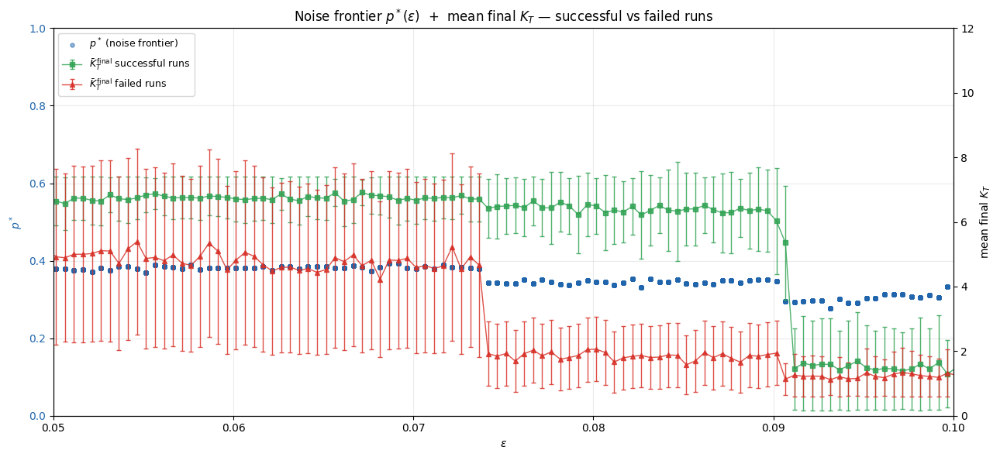

In [16]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL — Plot: ε vs p*  +  mean final K_T (successful vs failed runs)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np

# ── file already open; all arrays in scope ────────────────────────────────────

# ── X-axis zoom — adjust manually ────────────────────────────────────────────
X_LIM_LO = 0.05    # e.g. 0.01
X_LIM_HI = 0.1    # e.g. 0.10

# ── K_T right-axis cap — adjust manually ─────────────────────────────────────
K_YMAX = 12     # e.g. 30  — set None for auto

# ── Aggregate mean final K_T per unique epsilon ───────────────────────────────
unique_eps = np.unique(eps_arr)

eps_K_succ = [];  K_succ_mean = [];  K_succ_std = []
eps_K_fail = [];  K_fail_mean = [];  K_fail_std = []

n_omitted_succ = 0
n_omitted_fail = 0

for eps_val in unique_eps:
    mask_all  = (eps_arr == eps_val)
    mask_succ = mask_all &  success_arr
    mask_fail = mask_all & ~success_arr

    # ── successful runs ───────────────────────────────────────────────────────
    if np.any(mask_succ):
        K_final_succ = np.array([arr[-1] for arr in K_values_arr[mask_succ]])
        eps_K_succ.append(eps_val)
        K_succ_mean.append(K_final_succ.mean())
        K_succ_std.append(K_final_succ.std())
    else:
        n_omitted_succ += 1

    # ── failed runs ───────────────────────────────────────────────────────────
    if np.any(mask_fail):
        K_final_fail = np.array([arr[-1] for arr in K_values_arr[mask_fail]])
        eps_K_fail.append(eps_val)
        K_fail_mean.append(K_final_fail.mean())
        K_fail_std.append(K_final_fail.std())
    else:
        n_omitted_fail += 1

eps_K_succ = np.array(eps_K_succ);  K_succ_mean = np.array(K_succ_mean);  K_succ_std = np.array(K_succ_std)
eps_K_fail = np.array(eps_K_fail);  K_fail_mean = np.array(K_fail_mean);  K_fail_std = np.array(K_fail_std)

if n_omitted_succ:
    print(f"⚠ {n_omitted_succ} ε points had 0 successful runs — omitted from success K line")
if n_omitted_fail:
    print(f"⚠ {n_omitted_fail} ε points had 0 failed runs     — omitted from fail K line")

# ══════════════════════════════════════════════════════════════════════════════
# Plot
# ══════════════════════════════════════════════════════════════════════════════
fig, ax1 = plt.subplots(figsize=(13, 6))

color_p    = "#2166ac"   # blue  — p*
color_succ = "#31a354"   # green — successful K_T
color_fail = "#d73027"   # red   — failed K_T

# ── Left axis: p* ─────────────────────────────────────────────────────────────
ax1.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.5,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)
ax1.grid(True, alpha=0.25)

# ── Right axis: mean final K_T ────────────────────────────────────────────────
ax2 = ax1.twinx()

ax2.errorbar(eps_K_succ, K_succ_mean, yerr=K_succ_std,
             fmt="s-", color=color_succ, markersize=4, linewidth=1,
             capsize=2, alpha=0.85,
             label=r"$\bar{K}_T^{\,\mathrm{final}}$ successful runs")

ax2.errorbar(eps_K_fail, K_fail_mean, yerr=K_fail_std,
             fmt="^-", color=color_fail, markersize=4, linewidth=1,
             capsize=2, alpha=0.85,
             label=r"$\bar{K}_T^{\,\mathrm{final}}$ failed runs")

ax2.set_ylabel(r"mean final $K_T$", color="black")
ax2.tick_params(axis="y", labelcolor="black")

if K_YMAX is not None:
    ax2.set_ylim(0, K_YMAX)

# ── Combined legend ───────────────────────────────────────────────────────────
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

ax1.set_title(
    r"Noise frontier $p^*(\varepsilon)$  +  "
    r"mean final $K_T$ — successful vs failed runs"
)

# ── X-axis zoom ───────────────────────────────────────────────────────────────
if X_LIM_LO is not None or X_LIM_HI is not None:
    ax1.set_xlim(X_LIM_LO, X_LIM_HI)

plt.tight_layout()
plt.show()

In [30]:
# ── Diagnose the delta_theta_list structure ───────────────────────────────────
eps_lo, eps_hi = 0.07, 0.1   # ← set your epsilon range here

mask    = (eps_arr >= eps_lo) & (eps_arr <= eps_hi)
indices = np.where(mask)[0]

print(f"Showing {len(indices)} runs with ε ∈ [{eps_lo}, {eps_hi}]\n")

for i in indices:
    dtl = delta_theta_list_arr[i]
    kv  = K_values_arr[i]
    t   = T_arr[i]
    eps = eps_arr[i]
    print(f"Run {i:>4} | ε={eps:.6f} | T={t} | K_values={kv} | delta_theta_list={dtl}")

Showing 12000 runs with ε ∈ [0.07, 0.1]

Run 28000 | ε=0.070156 | T=5 | K_values=[1, 1, 1, 1, 7] | delta_theta_list=[0.25, 0.041099979173510326, 0.028832393098892933, 0.023466016428485947, 0.0058926404645063685]
Run 28001 | ε=0.070156 | T=5 | K_values=[1, 1, 1, 1, 7] | delta_theta_list=[0.25, 0.041133761256168674, 0.02884074522473784, 0.023461201834242468, 0.005910963469246841]
Run 28002 | ε=0.070156 | T=4 | K_values=[1, 1, 1, 3] | delta_theta_list=[0.25, 0.04106556535048604, 0.02881644984060236, 0.013736503017499568]
Run 28003 | ε=0.070156 | T=3 | K_values=[1, 1, 3] | delta_theta_list=[0.25, 0.04105861730153951, 0.013736503017499568]
Run 28004 | ε=0.070156 | T=4 | K_values=[1, 1, 1, 3] | delta_theta_list=[0.25, 0.04106556535048604, 0.02881844644314105, 0.013764602773605278]
Run 28005 | ε=0.070156 | T=4 | K_values=[1, 1, 1, 3] | delta_theta_list=[0.25, 0.041121653137437486, 0.028829822536085778, 0.01370721771247918]
Run 28006 | ε=0.070156 | T=3 | K_values=[1, 1, 5] | delta_theta_list=[